In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df=pd.read_csv("../data/processed/clean_sales.csv", parse_dates=["Order Date", "Ship Date"])
os.makedirs("../reports/figures", exist_ok=True)
df.shape

(9800, 21)

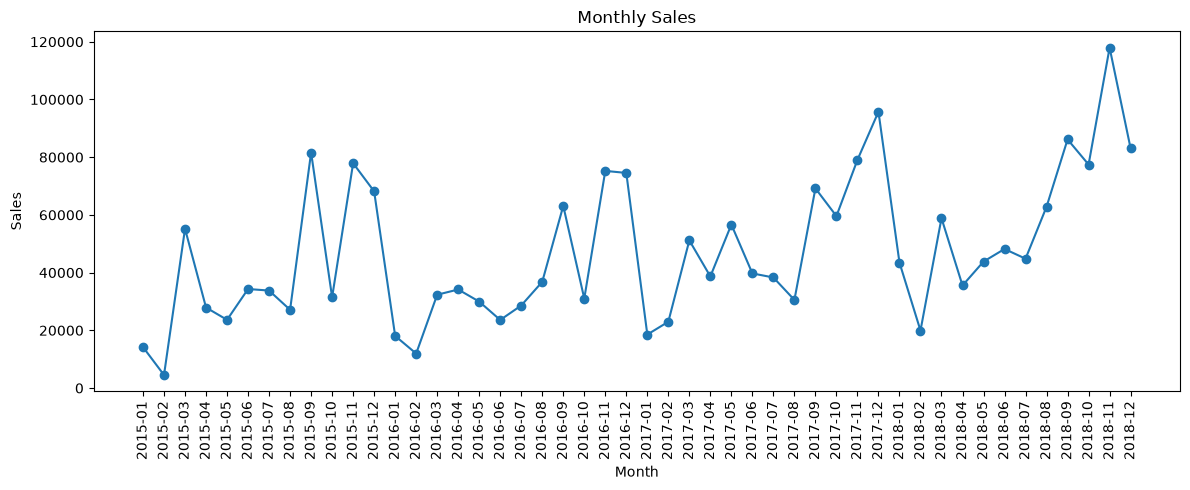

In [3]:
monthly = df.groupby("YearMonth")["Sales"].sum()

plt.figure(figsize=(12,5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.xticks(rotation=90)
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../reports/figures/monthly_sales.png")
plt.show()

#sales trend by year 
monthly sales from 2015 jan to 2018 december shows strong upward growth trend paired with highly predictable annual seasonality.
In 2015 jan started at below 2000 sales then annual lows rose 5000 above in feb to over 20000(2017-2018), while peaks climbed from 81k to nearly 118k.
Consistent seasonality, every year follows the same cycle: a sharp drop in feb, a strong rebound in march, a moderate dip in july/aug, and a massive surge peaking in november
Recent momentuntum from 2017-2018, sales jumped sunstantially in 2017 and maintained that higher performance throughout 2018 showing stronger summer stability of 40k-62k.

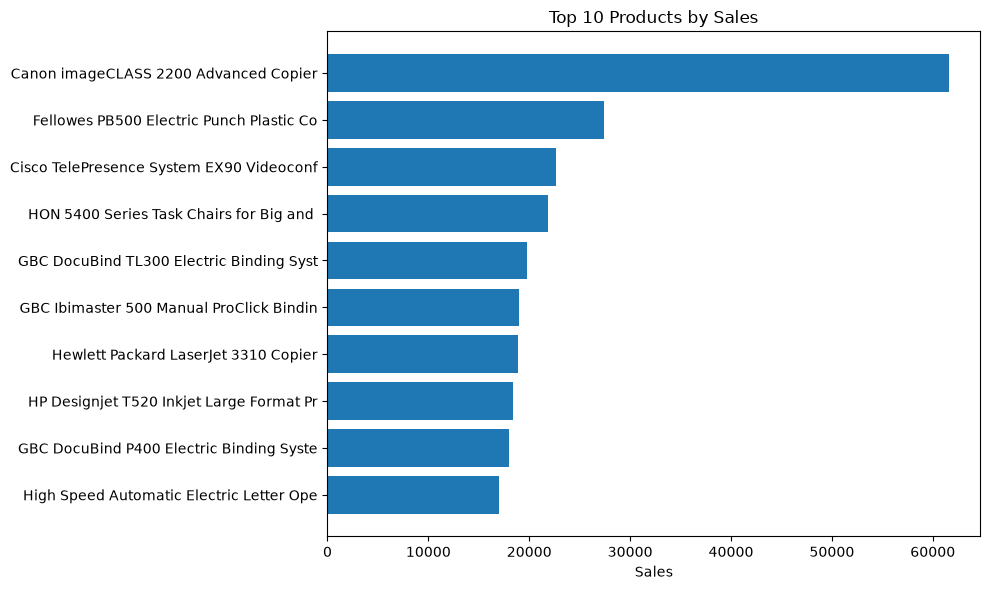

In [4]:
top_products = df.groupby("Product Name")["Sales"].sum().nlargest(10).sort_values()
names=[n[:40] for n in top_products.index]

plt.figure(figsize=(10,6))
plt.barh(names, top_products.values)
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.savefig("../reports/figures/top_products.png")
plt.show()

The bar charts shows the top ten products by sales, revesling a heavy skewed distribution led by a single dominant item.
the Canon imageCLASS 2200 Advanced Copier is the clear leader at roughly 61.5k, generating morethan double revenue of the second-palce Fellowes PB500 Binding machine about 27.5k
All remaining products ranked 3rd though 10th-mainly office equipment like tele systems, chairs, and printers.

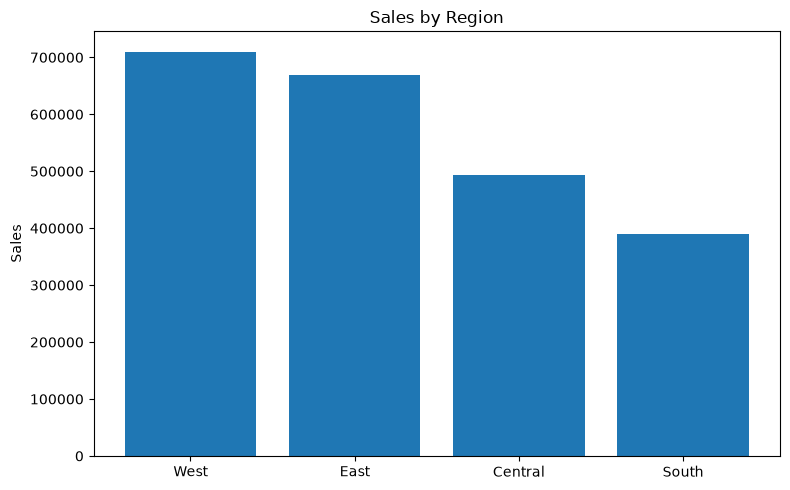

In [5]:
region=df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
plt.bar(region.index, region.values)
plt.title("Sales by Region")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../reports/figures/sales_by_region.png")
plt.show()

The bar chart is about Sales by region with West region got highest sales about 7L followed by East region about 6.6L, whereas Central Region has only 5L sales followed by South Region only 4L which is also lowest among all the regions.

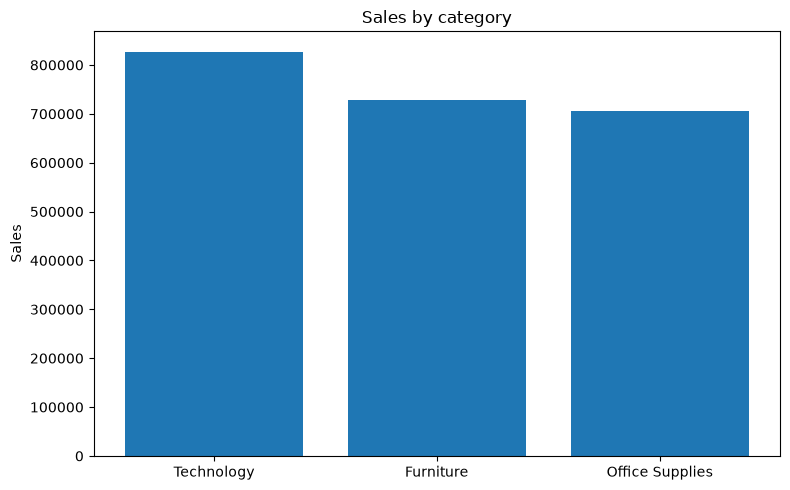

In [7]:
category=df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
plt.bar(category.index, category.values)
plt.title("Sales by category")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../reports/figures/sales_by_category")
plt.show()



The above bar graph shows the information about Sales by Category, x axis represents about Categories like tech, furniture, and ofice suppies, y axis Sales.
the highest sales is technology and lowest is furniture followed by office supplies. 

In [ ]:
print(df.groupby("Year")["Sales"].sum())
print(df.groupby("Region")["Sales"].sum().sort_values(ascending=False))
print(df.groupby("Category")["Sales"].sum().sort_values(ascending=False))
print(df.groupby("Month")["Sales"].sum().sort_values(ascending=False).head(3))

Year
2015    479856.2081
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64
Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64
Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64
Month
11    350161.7110
12    321480.1695
9     300103.4117
Name: Sales, dtype: float64


: 